# 1. Importing

In [3]:
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import gammaln, logsumexp
from scipy.stats import multivariate_normal

pd.set_option("display.max_columns", 30)
np.set_printoptions(precision=4, suppress=True)

print(f"NumPy: {np.__version__} | pandas: {pd.__version__}")

NumPy: 2.5.4 | pandas: 3.0.6


# 2. BOCPD mô phỏng chuỗi có changepoint

Tạo các đoạn Gauss nối tiếp, các đoạn thay đổi theo mean, hoặc phương sai. change_points lưu chỉ số quan sát đầu tiên thuộc đoạn mới

Số quan sát: 1,250
Change point thật: [250, 500, 750, 1000]
Các đoạn (mean, sd): [(0.0, 1.0), (2.0, 1.0), (2.0, 0.3), (-1.0, 0.3), (-1.0, 1.5)]


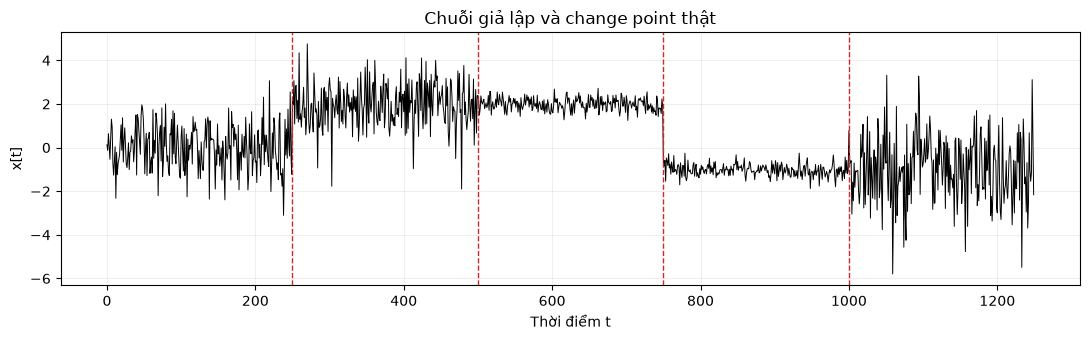

In [4]:
BOCPD_SEGMENTS = [(0.0, 1.0), (2.0, 1.0), (2.0, 0.3), (-1.0, 0.3), (-1.0, 1.5)]
SEGMENT_LENGTH = 250

def simulate_changepoints(segments=BOCPD_SEGMENTS, segment_length=SEGMENT_LENGTH, seed=0):
    """Sinh chuỗi 1D và trả về chỉ số đầu tiên của mỗi đoạn mới."""
    rng = np.random.default_rng(seed)
    values = np.concatenate(
        [rng.normal(mean, sd, segment_length) for mean, sd in segments]
    )
    change_points = np.arange(1, len(segments)) * segment_length
    return values, change_points

x, change_points = simulate_changepoints(seed=0)
print(f"Số quan sát: {len(x):,}")
print(f"Change point thật: {change_points.tolist()}")
print(f"Các đoạn (mean, sd): {BOCPD_SEGMENTS}")

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(x, linewidth=0.7, color="black")
for cp in change_points:
    ax.axvline(cp, color="tab:red", linestyle="--", linewidth=1)
ax.set(title="Chuỗi giả lập và change point thật", xlabel="Thời điểm t", ylabel="x[t]")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# 3. BOCPD, prior NIG va student

Giả sử mỗi đoạn có phân phối chuẩn với mean, variance. NIG cho phân phối dự báo student, priort được ước lượng từ chuỗi train mô phỏng riêng, không dùng chuỗi đang chạy để tránh lấy thông tin của test làm prior

In [5]:
@dataclass(frozen=True)
class NIGPrior:
    """sigma^2 ~ IG(alpha, beta), mu|sigma^2 ~ N(mu0, sigma^2/kappa)."""
    mu0: float
    kappa0: float
    alpha0: float
    beta0: float

    @classmethod
    def from_training_data(cls, training_values, kappa0=1.0, alpha0=2.0):
        values = np.asarray(training_values, dtype=float)
        values = values[np.isfinite(values)]
        if values.size == 0:
            raise ValueError("Training values must contain at least one finite observation.")
        variance = float(values.var())
        if variance <= 0:
            raise ValueError("Training variance must be positive.")
        return cls(
            mu0=float(values.mean()),
            kappa0=float(kappa0),
            alpha0=float(alpha0),
            beta0=variance * (alpha0 - 1.0),
        )

def student_t_logpdf(value, mu, kappa, alpha, beta):
    """Log predictive density under the Normal-Inverse-Gamma model."""
    degrees_freedom = 2.0 * alpha
    scale_squared = beta * (kappa + 1.0) / (alpha * kappa)
    standardized_squared = (value - mu) ** 2 / scale_squared
    return (
        gammaln((degrees_freedom + 1.0) / 2.0)
        - gammaln(degrees_freedom / 2.0)
        - 0.5 * np.log(np.pi * degrees_freedom * scale_squared)
        - (degrees_freedom + 1.0) / 2.0
        * np.log1p(standardized_squared / degrees_freedom)
    )

prior_training = np.random.default_rng(99).normal(0.0, 1.0, 500)
prior = NIGPrior.from_training_data(prior_training)
print("Prior estimated from separate training data:", prior)

Prior estimated from separate training data: NIGPrior(mu0=0.021150958644414013, kappa0=1.0, alpha0=2.0, beta0=1.0423010057306108)


# 4. BOCPD cập nhật posterior run length

Xử lý chuỗi từng điểm một để ước lượng xác suất xuất hiện changepoint

In [6]:
LAMBDA = 120
MAX_RUN_LENGTH = 600
K_CP = 10

class BOCPD:
    """Bayesian online change-point detection với likelihood Gaussian/NIG."""

    def __init__(self, prior, lam=LAMBDA, max_run_length=MAX_RUN_LENGTH, k_cp=K_CP):
        if lam <= 1:
            raise ValueError("lam must be greater than 1 for a valid constant hazard.")
        if max_run_length < 1 or k_cp < 0:
            raise ValueError("max_run_length must be positive and k_cp non-negative.")
        self.prior = prior
        self.max_run_length = int(max_run_length)
        self.k_cp = int(k_cp)
        self.log_hazard = np.log(1.0 / lam)
        self.log_growth_probability = np.log1p(-1.0 / lam)
        self.log_run_probability = np.array([0.0])
        self.mu = np.array([prior.mu0])
        self.kappa = np.array([prior.kappa0])
        self.alpha = np.array([prior.alpha0])
        self.beta = np.array([prior.beta0])

    def update(self, value):
        value = float(value)
        if not np.isfinite(value):
            raise ValueError("BOCPD input must be finite; handle missing values before calling update().")

        log_predictive = student_t_logpdf(
            value, self.mu, self.kappa, self.alpha, self.beta
        )
        log_growth = self.log_run_probability + log_predictive + self.log_growth_probability
        log_changepoint = logsumexp(
            self.log_run_probability + log_predictive + self.log_hazard
        )
        new_log_run_probability = np.concatenate(([log_changepoint], log_growth))
        new_log_run_probability -= logsumexp(new_log_run_probability)

        p = self.prior
        updated_mu = (self.kappa * self.mu + value) / (self.kappa + 1.0)
        updated_beta = self.beta + (
            self.kappa * (value - self.mu) ** 2 / (2.0 * (self.kappa + 1.0))
        )
        self.mu = np.concatenate(([p.mu0], updated_mu))
        self.kappa = np.concatenate(([p.kappa0], self.kappa + 1.0))
        self.alpha = np.concatenate(([p.alpha0], self.alpha + 0.5))
        self.beta = np.concatenate(([p.beta0], updated_beta))

        if new_log_run_probability.size > self.max_run_length + 1:
            new_log_run_probability = new_log_run_probability[: self.max_run_length + 1]
            new_log_run_probability -= logsumexp(new_log_run_probability)
            self.mu = self.mu[: self.max_run_length + 1]
            self.kappa = self.kappa[: self.max_run_length + 1]
            self.alpha = self.alpha[: self.max_run_length + 1]
            self.beta = self.beta[: self.max_run_length + 1]

        self.log_run_probability = new_log_run_probability
        probabilities = np.exp(new_log_run_probability)
        run_lengths = np.arange(probabilities.size)
        return {
            "p_r0": float(probabilities[0]),
            "expected_run": float(np.sum(run_lengths * probabilities)),
            "map_run": int(np.argmax(probabilities)),
            "cp_recent": float(probabilities[: self.k_cp + 1].sum()),
            "run_posterior": probabilities.copy(),
        }

def run_bocpd(values, prior, lam=LAMBDA, max_run_length=MAX_RUN_LENGTH, k_cp=K_CP):
    """Process observations one at a time and store posterior features."""
    model = BOCPD(prior, lam=lam, max_run_length=max_run_length, k_cp=k_cp)
    feature_rows = []
    posterior_matrix = np.zeros((len(values), max_run_length + 1))
    for t, value in enumerate(np.asarray(values, dtype=float)):
        result = model.update(value)
        posterior = result.pop("run_posterior")
        posterior_matrix[t, : posterior.size] = posterior
        feature_rows.append(result)
    return pd.DataFrame(feature_rows), posterior_matrix

bocpd_features, run_posterior = run_bocpd(x, prior)
hazard = 1.0 / LAMBDA
print(f"Hazard H: {hazard:.6f}")
print(f"p_r0 min/max: {bocpd_features['p_r0'].min():.6f} / {bocpd_features['p_r0'].max():.6f}")
print("p_r0 equals H at every time:", np.allclose(bocpd_features["p_r0"], hazard))
display(bocpd_features.iloc[np.unique(np.r_[change_points, change_points + 1, change_points + 5])].round(3))

Hazard H: 0.008333
p_r0 min/max: 0.008333 / 0.008333
p_r0 equals H at every time: True


,p_r0,expected_run,map_run,cp_recent
250,0.008,168.398,251,0.056
251,0.008,142.245,252,0.116
255,0.008,9.022,6,0.798
500,0.008,244.516,251,0.013
501,0.008,245.687,252,0.013
505,0.008,249.388,256,0.014
750,0.008,1.028,1,1.000
751,0.008,1.994,2,1.000
755,0.008,5.899,6,1.000
1000,0.008,1.213,1,1.000


## 4.1. Heatmap biểu diễn posterior run length theo thời gian

với cp_recent là xác suất đoạn hiện tại mới bắt đầu trong không quá k_cp quan sát gần nhất

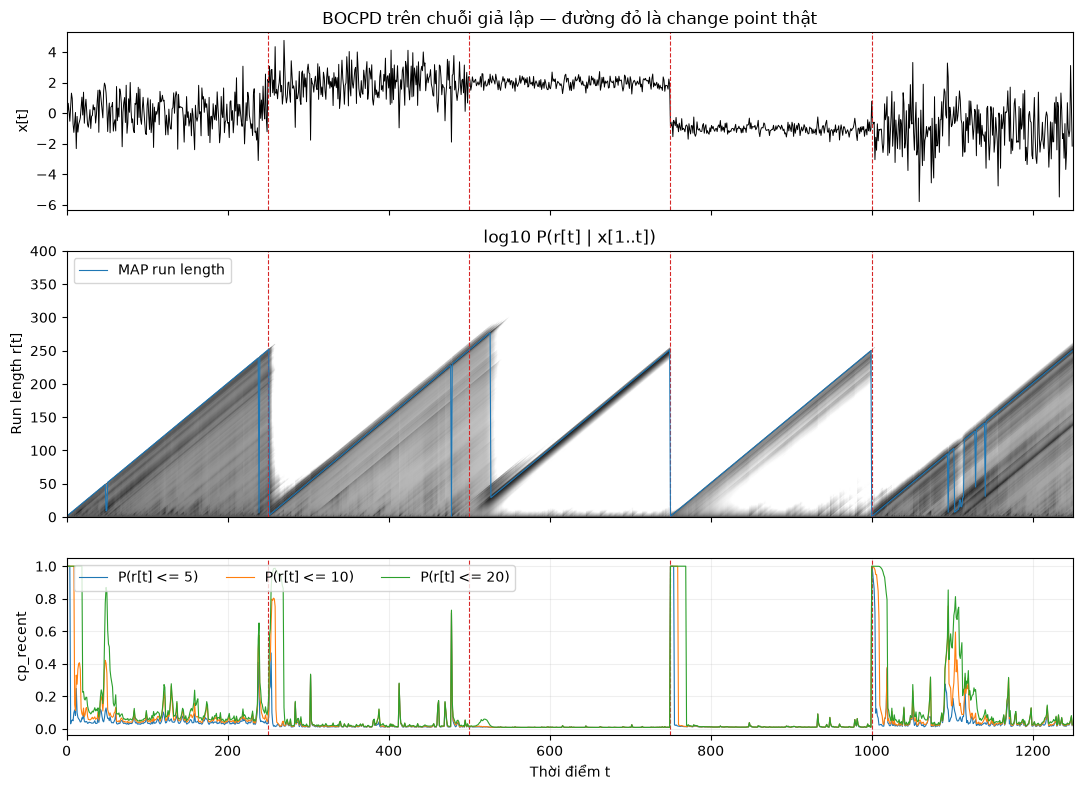

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, gridspec_kw={"height_ratios": [1, 1.5, 1]})
axes[0].plot(x, linewidth=0.7, color="black")
axes[0].set_ylabel("x[t]")
axes[0].set_title("BOCPD trên chuỗi giả lập — đường đỏ là change point thật")

for cp in change_points:
    for ax in axes:
        ax.axvline(cp, color="tab:red", linestyle="--", linewidth=0.8)

visible_run_lengths = min(400, run_posterior.shape[1])
axes[1].imshow(
    np.log10(run_posterior[:, :visible_run_lengths].T + 1e-12),
    aspect="auto",
    origin="lower",
    cmap="gray_r",
    vmin=-6,
    vmax=0,
    extent=[0, len(x), 0, visible_run_lengths],
)
axes[1].plot(bocpd_features["map_run"], color="tab:blue", linewidth=0.8, label="MAP run length")
axes[1].set_ylabel("Run length r[t]")
axes[1].set_title("log10 P(r[t] | x[1..t]) (với đậm là xác suất cao)")
axes[1].legend(loc="upper left")

for cp_window in (5, 10, 20):
    features, _ = run_bocpd(x, prior, k_cp=cp_window)
    axes[2].plot(features["cp_recent"], linewidth=0.8, label=f"P(r[t] <= {cp_window})")
axes[2].set_ylabel("cp_recent")
axes[2].set_xlabel("Thời điểm t")
axes[2].legend(loc="upper left", ncol=3)
axes[2].grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 4.2. Đánh giá changepoint trên mô phỏng

In [8]:
def detect_alarms(map_run, min_run_length=1):
    map_run = np.asarray(map_run)
    times = np.arange(map_run.size)
    decreases = np.r_[False, map_run[1:] < map_run[:-1]]
    alarm_times = times[decreases & (map_run >= min_run_length)]
    estimated_locations = alarm_times - map_run[alarm_times] + 1
    return alarm_times, estimated_locations

def match_alarms(alarm_times, estimated_locations, true_change_points, max_delay=50, location_tolerance=5):
    delays, location_errors, matched_alarm_indices = [], [], set()
    for change_point in true_change_points:
        matches = [
            i for i, alarm_time in enumerate(alarm_times)
            if change_point <= alarm_time <= change_point + max_delay
            and abs(estimated_locations[i] - change_point) <= location_tolerance
        ]
        if matches:
            first_match = matches[0]
            matched_alarm_indices.add(first_match)
            delays.append(int(alarm_times[first_match] - change_point))
            location_errors.append(int(estimated_locations[first_match] - change_point))
        else:
            delays.append(None)
            location_errors.append(None)
    false_alarm_count = len(alarm_times) - len(matched_alarm_indices)
    return delays, location_errors, false_alarm_count

alarm_rows = []
for seed in range(5):
    simulated_values, true_cps = simulate_changepoints(seed=seed)
    features, _ = run_bocpd(simulated_values, prior)
    alarm_times, locations = detect_alarms(features["map_run"])
    delays, errors, false_alarms = match_alarms(alarm_times, locations, true_cps)
    alarm_rows.append(
        {
            "seed": seed,
            "detected": sum(delay is not None for delay in delays),
            "delay_by_change_point": delays,
            "max_abs_location_error": max(
                (abs(error) for error in errors if error is not None), default=np.nan
            ),
            "false_alarms": false_alarms,
        }
    )
display(pd.DataFrame(alarm_rows))

,seed,detected,delay_by_change_point,max_abs_location_error,false_alarms
0,0,4,"[2, 27, 0, 0]",1,8
1,1,4,"[2, 34, 0, 1]",2,2
2,2,4,"[6, 23, 0, 1]",1,0
3,3,4,"[2, 26, 0, 0]",1,2
4,4,4,"[2, 25, 0, 2]",5,6


# 5. Gauss HMM mô phỏng 3 regime ẩn

với 2 đặc trưng mỗi bước là return và log-volatility. Regime ẩn có xác suất chuyển tiếp markov, phân phối quan sát mỗi regime là Gauss nhiều biến

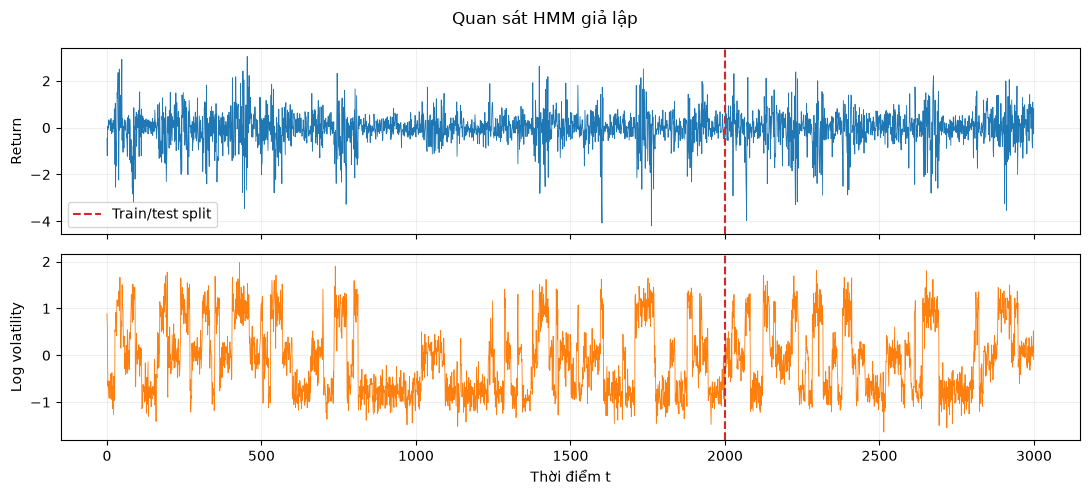

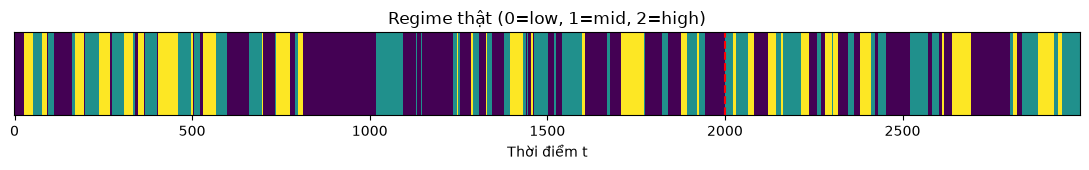

In [9]:
TRUE_MEANS = np.array([[0.00, -0.8], [0.02, 0.0], [-0.15, 1.0]])
TRUE_SDS = np.array([[0.30, 0.25], [0.60, 0.25], [1.20, 0.30]])
TRUE_TRANSITIONS = np.array(
    [[0.97, 0.02, 0.01], [0.02, 0.96, 0.02], [0.02, 0.04, 0.94]]
)

def simulate_hmm(n_steps=3000, seed=0):
    rng = np.random.default_rng(seed)
    n_states = TRUE_TRANSITIONS.shape[0]
    states = np.empty(n_steps, dtype=int)
    states[0] = rng.integers(n_states)
    for t in range(1, n_steps):
        states[t] = rng.choice(n_states, p=TRUE_TRANSITIONS[states[t - 1]])
    observations = (
        TRUE_MEANS[states]
        + TRUE_SDS[states] * rng.standard_normal((n_steps, TRUE_MEANS.shape[1]))
    )
    return observations, states

X, states_true = simulate_hmm(n_steps=3000, seed=0)
split_at = 2000
X_train, X_test = X[:split_at], X[split_at:]
states_test = states_true[split_at:]

fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(X[:, 0], linewidth=0.6)
axes[0].set_ylabel("Return")
axes[1].plot(X[:, 1], linewidth=0.6, color="tab:orange")
axes[1].set_ylabel("Log volatility")
axes[1].set_xlabel("Thời điểm t")
for ax in axes:
    ax.axvline(split_at, color="tab:red", linestyle="--", label="Train/test split")
    ax.grid(alpha=0.2)
axes[0].legend()
fig.suptitle("Quan sát HMM giả lập")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 1.8))
ax.imshow(states_true[np.newaxis, :], aspect="auto", interpolation="nearest", cmap="viridis")
ax.axvline(split_at, color="red", linestyle="--")
ax.set(title="Regime thật (0=low, 1=mid, 2=high)", xlabel="Thời điểm t", yticks=[])
plt.tight_layout()
plt.show()

# 6. Gauss HMM với Baum-Welch tự cài đặt

Baum-Welch iterations: 10
Final train log-likelihood: -2031.624


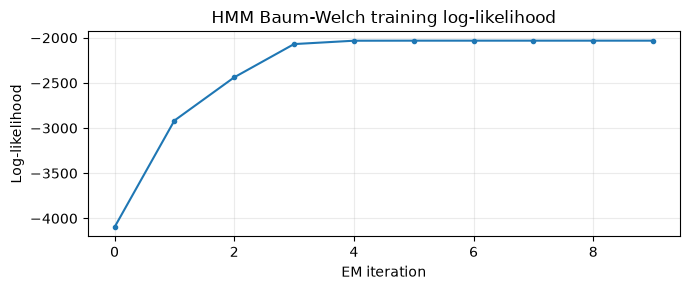

In [10]:
def gaussian_log_emissions(observations, means, covariances):
    """log p(x_t | state=k), cho mọi t và k."""
    return np.column_stack(
        [
            multivariate_normal.logpdf(
                observations, mean=means[k], cov=covariances[k], allow_singular=False
            )
            for k in range(len(means))
        ]
    )

def forward_backward(log_emissions, initial_probabilities, transition_matrix):
    """Scaled forward-backward; returns gamma, xi and sequence log likelihood."""
    n_steps, n_states = log_emissions.shape
    log_initial = np.log(np.clip(initial_probabilities, 1e-300, None))
    log_transition = np.log(np.clip(transition_matrix, 1e-300, None))

    log_alpha = np.empty((n_steps, n_states))
    log_scales = np.empty(n_steps)
    unscaled = log_initial + log_emissions[0]
    log_scales[0] = logsumexp(unscaled)
    log_alpha[0] = unscaled - log_scales[0]
    for t in range(1, n_steps):
        unscaled = logsumexp(log_alpha[t - 1][:, None] + log_transition, axis=0)
        unscaled = unscaled + log_emissions[t]
        log_scales[t] = logsumexp(unscaled)
        log_alpha[t] = unscaled - log_scales[t]

    log_beta = np.zeros((n_steps, n_states))
    for t in range(n_steps - 2, -1, -1):
        log_beta[t] = logsumexp(
            log_transition + log_emissions[t + 1][None, :] + log_beta[t + 1][None, :],
            axis=1,
        ) - log_scales[t + 1]

    log_gamma = log_alpha + log_beta
    log_gamma -= logsumexp(log_gamma, axis=1, keepdims=True)
    gamma = np.exp(log_gamma)

    xi = np.empty((n_steps - 1, n_states, n_states))
    for t in range(n_steps - 1):
        log_xi_t = (
            log_alpha[t][:, None]
            + log_transition
            + log_emissions[t + 1][None, :]
            + log_beta[t + 1][None, :]
            - log_scales[t + 1]
        )
        log_xi_t -= logsumexp(log_xi_t)
        xi[t] = np.exp(log_xi_t)

    return gamma, xi, float(log_scales.sum())

def fit_gaussian_hmm(observations, n_states=3, max_iterations=100, tolerance=1e-4, min_covar=1e-3):
    """Train full-covariance Gaussian HMM with Baum-Welch on one sequence."""
    observations = np.asarray(observations, dtype=float)
    if observations.ndim != 2 or not np.isfinite(observations).all():
        raise ValueError("observations must be a finite 2D array (time, features).")
    if len(observations) <= n_states:
        raise ValueError("Need more observations than hidden states.")

    n_steps, n_features = observations.shape
    volatility_column = n_features - 1
    initial_labels = np.argsort(np.argsort(observations[:, volatility_column])) * n_states // n_steps
    initial_labels = np.minimum(initial_labels, n_states - 1)

    global_covariance = np.cov(observations, rowvar=False) + min_covar * np.eye(n_features)
    means = np.vstack(
        [observations[initial_labels == state].mean(axis=0) for state in range(n_states)]
    )
    covariances = np.stack([global_covariance.copy() for _ in range(n_states)])
    initial_probabilities = np.full(n_states, 1.0 / n_states)
    transition_counts = np.ones((n_states, n_states))
    np.fill_diagonal(transition_counts, 10.0)
    for left, right in zip(initial_labels[:-1], initial_labels[1:]):
        transition_counts[left, right] += 1.0
    transition_matrix = transition_counts / transition_counts.sum(axis=1, keepdims=True)

    log_likelihoods = []
    for iteration in range(max_iterations):
        log_emissions = gaussian_log_emissions(observations, means, covariances)
        gamma, xi, log_likelihood = forward_backward(
            log_emissions, initial_probabilities, transition_matrix
        )
        log_likelihoods.append(log_likelihood)

        state_weights = gamma.sum(axis=0)
        initial_probabilities = gamma[0] / gamma[0].sum()
        transition_matrix = xi.sum(axis=0) / np.maximum(
            gamma[:-1].sum(axis=0)[:, None], 1e-12
        )
        transition_matrix = np.clip(transition_matrix, 1e-12, None)
        transition_matrix /= transition_matrix.sum(axis=1, keepdims=True)

        means = (gamma.T @ observations) / state_weights[:, None]
        covariances = np.empty((n_states, n_features, n_features))
        for state in range(n_states):
            centered = observations - means[state]
            covariances[state] = (
                (centered * gamma[:, state, None]).T @ centered / state_weights[state]
            ) + min_covar * np.eye(n_features)

        if iteration > 0 and abs(log_likelihoods[-1] - log_likelihoods[-2]) < tolerance:
            break

    model = {
        "initial_probabilities": initial_probabilities,
        "transition_matrix": transition_matrix,
        "means": means,
        "covariances": covariances,
        "log_likelihoods": log_likelihoods,
        "iterations": len(log_likelihoods),
    }
    return model

hmm = fit_gaussian_hmm(X_train, n_states=3, max_iterations=100)
print(f"Baum-Welch iterations: {hmm['iterations']}")
print(f"Final train log-likelihood: {hmm['log_likelihoods'][-1]:.3f}")
plt.figure(figsize=(7, 3))
plt.plot(hmm["log_likelihoods"], marker=".")
plt.title("HMM Baum-Welch training log-likelihood")
plt.xlabel("EM iteration")
plt.ylabel("Log-likelihood")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# 7. HMM forward filter và gán nhãn state

Forward filter tính xác suất P(z_t | x_1 ... x_t) bằng đệ quy 1 chiều, mỗi hàng kết quả là phân phối xác suất trên các state

In [11]:
def forward_filter(observations, model):
    """Filtered state probabilities P(z_t | x_1..t), without a backward pass."""
    observations = np.asarray(observations, dtype=float)
    if observations.ndim != 2 or not np.isfinite(observations).all():
        raise ValueError("observations must be a finite 2D array (time, features).")

    log_emissions = gaussian_log_emissions(
        observations, model["means"], model["covariances"]
    )
    log_initial = np.log(np.clip(model["initial_probabilities"], 1e-300, None))
    log_transition = np.log(np.clip(model["transition_matrix"], 1e-300, None))
    n_steps, n_states = log_emissions.shape
    log_filtered = np.empty((n_steps, n_states))

    current = log_initial + log_emissions[0]
    log_filtered[0] = current - logsumexp(current)
    for t in range(1, n_steps):
        current = logsumexp(log_filtered[t - 1][:, None] + log_transition, axis=0)
        current = current + log_emissions[t]
        log_filtered[t] = current - logsumexp(current)
    return np.exp(log_filtered)

def smooth_probabilities(observations, model):
    """Forward-backward posterior P(z_t | x_1..T), for leakage comparison only."""
    log_emissions = gaussian_log_emissions(
        np.asarray(observations, dtype=float), model["means"], model["covariances"]
    )
    gamma, _, _ = forward_backward(
        log_emissions, model["initial_probabilities"], model["transition_matrix"]
    )
    return gamma

state_order = np.argsort(hmm["means"][:, 1])
state_names = ["low", "mid", "high"]
filtered = forward_filter(X_test, hmm)
smoothed_for_comparison = smooth_probabilities(X_test, hmm)
filtered_mapped = filtered[:, state_order]
smoothed_mapped = smoothed_for_comparison[:, state_order]
p_high = filtered_mapped[:, -1]

state_rows = []
for label_index, original_state in enumerate(state_order):
    state_rows.append(
        {
            "label": state_names[label_index],
            "original_state": int(original_state),
            "mean_return": hmm["means"][original_state, 0],
            "mean_log_vol": hmm["means"][original_state, 1],
            "var_return": hmm["covariances"][original_state, 0, 0],
            "var_log_vol": hmm["covariances"][original_state, 1, 1],
            "expected_duration": 1.0 / (1.0 - hmm["transition_matrix"][original_state, original_state]),
        }
    )
display(pd.DataFrame(state_rows).round(3))

filtered_accuracy = np.mean(filtered_mapped.argmax(axis=1) == states_test)
smoothed_accuracy = np.mean(smoothed_mapped.argmax(axis=1) == states_test)
print(f"Filtered regime accuracy: {filtered_accuracy:.3f}")
print(f"Smoothed accuracy (future-aware; comparison only): {smoothed_accuracy:.3f}")
print(f"Mean filtered P(high) when true state is high: {p_high[states_test == 2].mean():.3f}")
print(f"Mean filtered P(high) when true state is low:  {p_high[states_test == 0].mean():.3f}")
print("Filtered probabilities sum to 1:", np.allclose(filtered.sum(axis=1), 1.0))
display(
    pd.DataFrame(
        filtered_mapped[:10],
        columns=["P(low | past)", "P(mid | past)", "P(high | past)"],
    ).round(3)
)

,label,original_state,mean_return,mean_log_vol,var_return,var_log_vol,expected_duration
0,low,0,0.024,-0.803,0.089,0.060,31.061
1,mid,1,0.026,0.008,0.361,0.068,18.846
2,high,2,-0.238,1.029,1.476,0.095,17.386


Filtered regime accuracy: 0.984
Smoothed accuracy (future-aware; comparison only): 0.995
Mean filtered P(high) when true state is high: 0.972
Mean filtered P(high) when true state is low:  0.000
Filtered probabilities sum to 1: True


,P(low | past),P(mid | past),P(high | past)
0,0.000,0.000,1.000
1,0.000,0.864,0.136
2,0.000,0.964,0.036
3,0.009,0.991,0.000
4,0.000,1.000,0.000
5,0.000,1.000,0.000
6,0.001,0.999,0.000
7,0.000,0.996,0.004
8,0.000,1.000,0.000
9,0.000,1.000,0.000


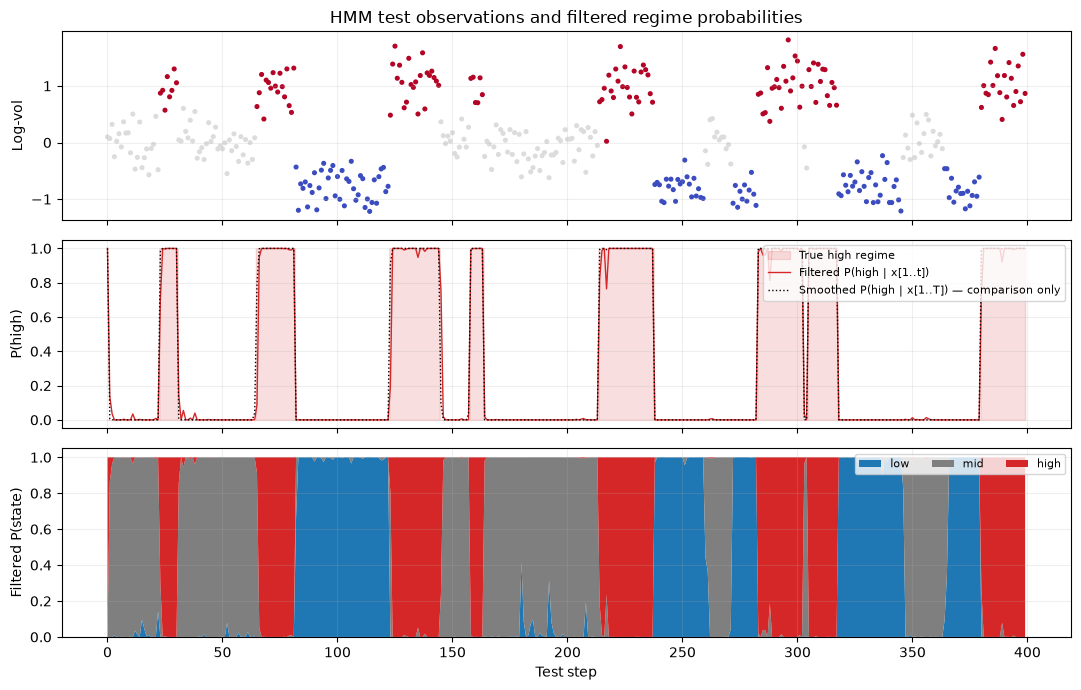

In [12]:
window = slice(0, 400)
time = np.arange(len(X_test))[window]
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
axes[0].scatter(time, X_test[window, 1], c=states_test[window], cmap="coolwarm", s=7)
axes[0].set_ylabel("Log-vol")
axes[0].set_title("HMM test observations and filtered regime probabilities")
axes[1].fill_between(time, 0, (states_test[window] == 2), color="tab:red", alpha=0.15, step="mid", label="True high regime")
axes[1].plot(time, p_high[window], color="tab:red", linewidth=1, label="Filtered P(high | x[1..t])")
axes[1].plot(time, smoothed_mapped[window, -1], color="black", linestyle=":", linewidth=1, label="Smoothed P(high | x[1..T]) — comparison only")
axes[1].set_ylabel("P(high)")
axes[1].legend(loc="upper right", fontsize=8)
axes[2].stackplot(time, filtered_mapped[window].T, colors=["tab:blue", "tab:gray", "tab:red"], labels=state_names)
axes[2].set_ylabel("Filtered P(state)")
axes[2].set_xlabel("Test step")
axes[2].legend(loc="upper right", fontsize=8, ncol=3)
for ax in axes:
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# 8. Kiểm tra
Thay dữ liệu sau 1 thời điểm t. BOCPD features và xác suất filtered HMM đến hết thời gian này phải được giữ nguyên

In [13]:
t_bocpd = 600
x_changed = x.copy()
x_changed[t_bocpd + 1:] = np.random.default_rng(1).normal(
    5.0, 3.0, len(x) - t_bocpd - 1
)
features_original, _ = run_bocpd(x, prior)
features_changed, _ = run_bocpd(x_changed, prior)
bocpd_prefix_difference = np.max(
    np.abs(
        features_original.iloc[: t_bocpd + 1].to_numpy()
        - features_changed.iloc[: t_bocpd + 1].to_numpy()
    )
)
print(f"BOCPD max feature difference through t={t_bocpd}: {bocpd_prefix_difference:.2e}")
assert bocpd_prefix_difference == 0.0
assert not np.allclose(
    features_original.iloc[t_bocpd + 1:].to_numpy(),
    features_changed.iloc[t_bocpd + 1:].to_numpy(),
)

candidate_times = np.flatnonzero(
    (np.arange(len(X_test)) >= 600) & (p_high > 0.2) & (p_high < 0.8)
)
if candidate_times.size == 0:
    raise RuntimeError("No uncertain filtered HMM point available for look-ahead demonstration.")
t_hmm = int(candidate_times[0])
X_test_changed = X_test.copy()
X_test_changed[t_hmm + 1:] = (
    TRUE_MEANS[0]
    + TRUE_SDS[0] * np.random.default_rng(5).standard_normal(
        (len(X_test) - t_hmm - 1, X_test.shape[1])
    )
)

filtered_original = forward_filter(X_test, hmm)
filtered_changed = forward_filter(X_test_changed, hmm)
smoothed_original = smooth_probabilities(X_test, hmm)
smoothed_changed = smooth_probabilities(X_test_changed, hmm)
filtered_difference = np.max(
    np.abs(filtered_original[: t_hmm + 1] - filtered_changed[: t_hmm + 1])
)
smoothed_difference_at_t = np.max(
    np.abs(smoothed_original[t_hmm] - smoothed_changed[t_hmm])
)
print(f"HMM filtered max difference through t={t_hmm}: {filtered_difference:.2e}")
print(f"HMM smoothed max difference at t={t_hmm}: {smoothed_difference_at_t:.3f}")
assert filtered_difference == 0.0
assert smoothed_difference_at_t > 1e-6
print("PASS: filtered outputs do not depend on future observations; smoothed outputs do.")

BOCPD max feature difference through t=600: 0.00e+00
HMM filtered max difference through t=646: 0.00e+00
HMM smoothed max difference at t=646: 0.447
PASS: filtered outputs do not depend on future observations; smoothed outputs do.
